# **Applied Data Analysis - Project Milestone P2**
## *How to be funny, for dummies.*

**<font size="4">Team: *JSON Derulo*</font>**<br>
- Adrián Fernández Lojo - adrian.fernandezlojo@epfl.ch
- Hanna Zwygart - hanna.zwygart@epfl.ch
- Jeremy Alexandre Serillon - jeremy.serillon@epfl.ch
- Mariem Maazoun - mariem.maazoun@epfl.ch
- Marina-Carmen Meredith Romero - marina.meredith@epfl.ch

Github repository: https://github.com/epfl-ada/ada-2025-project-json-derulo
<br><br><br>
_Note: Generative AI was used in this project to help us code some functions._
<br><br><br>

<!-- 
Make sure to read the [P2_README.md](P2_README.md) file.
<br><br>

**<font size="4">Table of Content</font>**

0. [Introduction](#0.-Introduction) <br>
0.1. [Abstract](#01-abstract) <br>
0.2. [Problematic](#02-problematic) <br>
0.3. [Dataset Description](#03-dataset-description) <br>
1. [General Data Visualizations](#1-general-data-visualizations) <br>
1.1. [Global Overview](#11-global-overview) <br>
1.2. [Overview of Contest Data](#12-overview-of-contest-data) <br>
1.3. [Intra Contest Overview](#13-intra-contest-overview) <br>
2. [Data pre-processing & cleaning](#2-data-pre-processing--cleaning) <br>
2.1. [Data Wrangling (filter, transform, ...)](#21-data-wrangling-filter-transform-) <br>
2.2. [Dataset Augmentation (enrich and adding new data)](#22-dataset-augmentation-enrich-and-adding-new-data) <br>
3. [Theme Analysis](#3-theme-analysis)
4. [Structural Analysis](#4-structural-analysis)
5. [Semantic Analysis](#5-semantic-analysis)
6. [Context Analysis](#6-context-analysis)
7. [Conclusion](#7-conclusion) -->

## 0. Introduction



### 0.1. Abstract

_"A day without laughter is a day wasted"_ - Charlie Chaplin

Each week, the NewYorker magazine provides an original cartoon, with a missing caption. Readers are thus invited to not only caption that week's contest, but also rate the previous week's image. 

In recent years, meme culture, and internet culture overall, has consistently prioritized shorter, and trending jokes. Tweets, TikToks, and even indirectly related formats, are tending to become shorter and have visual support. This is one of the many factors that could define how an image supported joke lands.

In this project, we have decided to dive into the NewYorker's caption contest dataset, which will give us great insights into humour, one of the most complex forms of human communication. We aim to discover the themes, structures, semantics, context and other subtleties that make something "funny".

<!-- Being funny is generally defined as a deeply cultural, societal and even contextual skill. When looking at our dataset, naturally, the following questions emerged : How can funniness be quantified ? Is humor objective ? 
Humour is a good reflection of society. The NYT caricatures are iconic, and captures years of societal, political and even government changes. We were therefore naturally drawn towards this dataset. We thought it would be interesting to see the evolutions of these captions over multiple years, through COVID etc…
The story we would like to tell is the story of what defines a funny or unfunny joke.
How do people react to the semantics and structure of a joke?  In our opinion, we would expect certain themes or joke structure to work better than others.  -->

### 0.2. Problematic

**Main problematics** <br>
How can we qualify and quantify jokes in terms of themes, structures and semantics (type of joke)? 

**Research questions and directions**<br>
Based on the objectives presented in the abstract, we aim to tackle the following concrete questions : 

1. Theme analysis:<br>
   1.a) How do theme relationships work between image and their text prompt ? <br>
   1.b) Are some images themes inherently funnier ? <br>
   1.c) Are semantically distant image–caption theme pairs (lower cosine similarity / higher distance) 
      - i funnier and/or 
      - ii less/more frequent than semantically similar pairs?

2. Structural analysis: <br>
   2.a) Are shorter jokes funnier?<br>
   2.b) Are jokes with specific vocabulary more effective?

3. Semantic analysis:<br>
   3.a) Which of Berger Humor's categories perform best ?

4. Temporal analysis : <br>
   4.a) What patterns emerge when visualizing timing-relation questions accross time ?

### 0.3. Dataset description

The NewYorker's caption contest dataset follows the structure depicted below:
```bash
.
├── contests.json
├── data/
│   ├── 510.csv
│   ├── 511.csv
│   ...
│   ├── 894.csv
│   └── 895.csv
└── images/
    ├── 510.jpg
    ├── 511.jpg
    ...
    ├── 894.jpg
    └── 895.jpg
```

The ```contest.json``` holds the following data: _image path_, corresponding .csv _data path_ & _metadata_. The _metadata_ is a dictionary containing: the number of captions (present in the corresponding .csv file), image locations description (e.g. "streets", "a field", "wedding", ...), images descriptions ("A man walks outside."), image uncanny descriptions, related questions & related Wikipedia entities.

The corresponding contest image csv files, e.g. ```510.csv```, hold the following keys: <br>
funniness rank 'rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny' & 'funny'.


#### Scoring methods:

Linkert scale method:

|      Rating    |  Score |
| :-------------:| :----: |
| not funny      |  +1    |
| somewhat_funny |  +2    |
| funny          |  +3    |

The mean is the Arithmetic mean of all the scores for a specific caption $\sum_{i=1}^{n} score_i / n$ where $n$ is the number of votes <br>

The precision is the Standard Error of the Mean (SEM) $\sigma / \sqrt{n}$ where $\sigma$ is the standard deviation of the scores $\sigma^2=\frac{1}{n}\sum_{i=1}^{n}(mean-score_i)^2$. <br>



The dataframes are already sorted by the mean so we wont change the order <br>


### 0.4. Our Data Story

We developed our website, available at this [link](https://hzwygart.github.io/ada-2025-project-json-derulo/), following the overall structure and narrative of this notebook. 
The website was designed with accessibility and user engagement in mind. Interactive components and progressive explanations allow readers to explore the data at their own pace, while maintaining a coherent narrative structure. We also tried to replicate the NewYorker-style witty and snarky editorial writing.


Several interactive elements were added to enrich the user experience:

#### 0.4.1. Caption Analyzer

The *Caption Analyzer* is designed to assess how well readers have internalized the insights derived from the structural analysis (see Section 4.1). By actively engaging with the content, users can test their understanding of what makes a caption effective and humorous.

#### 0.4.2. Ending Quiz

For the final quiz, we carefully selected the cartoons on which users are tested. This selection was based on the function `print_top3_biggest_deltas`, which relies on the `computing_deltas` method. The latter computes, for each contest, the score margin (delta) between the two highest-rated captions, using their mean funniness scores extracted from the cleaned CSV files. This margin serves as a quantitative measure of how decisively the top caption outperformed the runner-up.

We considered contests with larger deltas to be particularly relevant, as they correspond to cartoons with a more clearly identifiable “objectively funniest” caption. Using this criterion, we selected **contest 600, contest 690, and contest 555**.

#### 0.4.3. Visualizations

Finally, we chose to incorporate external tools such as **Flourish** and **Plotly** in order to produce visually engaging and accessible interactive visualizations, enhancing both clarity and aesthetic appeal. We have also established a plotly theme, of colors and typos, to make the reader-experience as immersive and coherent as possible.


By combining statistical analysis with interactive elements, our datastory aims not only to present results, but also to encourage users to actively reflect on what makes a caption successful.



## 1. General Data Visualizations

In [29]:

# General
import os
from pathlib import Path


# data manipulation
import json
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
#for theme
#%run ../../docs/plotly_theme.ipynb # 




# ====== 3. THEME DETECTION ======= #
# NLP
from sentence_transformers import SentenceTransformer
from sklearn.cluster import MiniBatchKMeans

# Stats
from scipy import stats
from scipy.stats import spearmanr
import statsmodels.formula.api as smf

# custom dataloading and utils functions
import Utils.utils_themes_P3 as p3_themes
import Utils.mariem_p3 as mp3



# ====== 4. TODO ======= #

# custom 
# import utils_structural_analysis as ut #TODO changer le path to utils.utils_structural_analysis



# Interactive Jupyter
from IPython.display import display
from IPython.core.interactiveshell import InteractiveShell

# others
import contractions
from scipy.stats import pearsonr, ttest_ind, f_oneway
import nltk
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
nltk.download('stopwords')

# Custom utility python files
# import Utils.visualization as viz # custom visualization utils in '/utils/visualization.py'
#import Utils.joke_classification as jc # custom joke classification utils in '/utils/joke_classification.py'
# import utils.data_augmentation as da # custom data augmentation utils in '/utils/data_augmentations.py'
# import utils.data_augmentation as da # custom data augmentation utils in '/utils/data_augmentations.py'



[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/jeremyserillon/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [21]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'
CLASS_DIR=DATA_DIR / 'LLM_classifications'
# TODO creer un path pour le file de Marina

# themes analysis
THEME_PATH = DATA_DIR / "THEMES_RESULTS_V4" 

DOC_THEMES_DIR = THEME_PATH /'docs_with_themes.csv'
SIMILARITY_PATH = THEME_PATH / "theme_similarity_by_theme_id.csv"
THEMES_TFIDF_DIR = THEME_PATH /'TF_IDF_themes_scores.csv'
THEMES_DIR = THEME_PATH /'themes.csv'
GEN_LABELS_PATH = THEME_PATH / 'Themes_V4_gen_labels.csv'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)
print("CLASS_DIR:     ", CLASS_DIR)

Project path setup:
PROJECT_ROOT:   /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo
FIGURES_DIR:    /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/figures

DATA_DIR:       /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest
JSON_DIR:       /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/contests.json
CSV_DIR:        /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/data
CSV_CLEAN_DIR:  /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/data_cleaned
IMG_DIR:        /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/images
CLASS_DIR:      /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/LLM_classifications


### 1.1. Global Overview

Let us take a look at our raw dataset. Feel free to play with the slider to visualize different contest images and corresponding metadatas (if any).

In [ ]:
# Load the JSON file => pandas DataFrame
file_path = str(JSON_DIR)
with open(file_path, "r") as file:
    contests = json.load(file)
contests_df = pd.DataFrame(contests)

# Visualize the contests with interactive viewer
viewer = viz.make_contest_viewer(contests_df, file_path)
display(viewer)

Once you have selected a contest ID with the slider, run the next cell to visualize some plots of the corresponding .CSV file.

In [ ]:
contest_id = int(viewer.slider.value)
print("Current selected 'contest_id' =", contest_id)

# Load corresponding CSV file
contest_row = contests_df[contests_df["contest_id"] == contest_id]
if not contest_row.empty:
    csv_rel_path = contest_row.iloc[0]["data"]
    csv_path = os.path.join(os.path.dirname(file_path), csv_rel_path)
    if os.path.exists(csv_path):
        df_current = pd.read_csv(csv_path)
        viz.plot_df_pairgrid(df_current, cols=["mean","precision","votes", "not_funny",
                                               "somewhat_funny", "funny"],
                             trace="none", figsize=(8,8),
                             include_upper=False, diagonal="name")
    else:
        print(f"CSV file not found at {csv_path}")
else:
    print(f"No contest found for contest_id {contest_id}")

In [ ]:
print(contests_df.count())

votes distribution

In [ ]:
filename = f"{contest_id}.csv"
file_path = os.path.join(CSV_DIR, filename)
df=pd.read_csv(file_path)
viz2.plot_divised_histo_stacked(pd.read_csv(file_path))

means distribution :

In [ ]:
viz2.scatter_error(df)
viz2.plot_divised_scatter_error(df)

It looks like a heavy-tailed distribution!

Some data exploration : <br>
<br>
-Top1 Means vs all context

In [ ]:
viz2.top1_means_vs_contests(CSV_DIR,IMG_DIR)

-Number of caption vs contests

In [ ]:
viz2.plot_number_of_captions_vs_contests(CSV_DIR,IMG_DIR)

it seems that contest 716 might be an outlier <br>
<br>

- Funy captions distribution

In [ ]:
viz2.plot_funny_dist(CSV_DIR)

We should perhaps look more into contest 744. <br>

### 1.2. Overview of Contest Data (```contests.json``` file)

- missing metadatas (dictionaries): 144
- 2 missing contest: 525 & 540

In [ ]:
# check missing contest (in the interval 510-895)
missing_contest = []
missing_csv = []
for id in range(510, 896):
    # missing contest id in json file
    if id not in contests_df['contest_id'].values:
        missing_contest.append(id)
    # missing csv file in DATA_DIR
    csv_path = CSV_DIR / f"{id}.csv"
    if not csv_path.exists():
        missing_csv.append(id)
        
print("Missing contest IDs in json file:", missing_contest)
print("Contests with missing CSV files in DATA_DIR:", missing_csv)

In [ ]:
# check missing metadata for each (present) contest id
missing_metadata = contests_df[contests_df['metadata'].isnull()]
print(f"Count of missing metadata: {len(missing_metadata)}")
print("Contest IDs with missing metadata:", missing_metadata['contest_id'].tolist())

### 1.3. Intra Contest Overview (.csv files)

- corrupted rows: in all ... we have 64'007 corrupted rows in all of the .csv files for a total of 2'292'677 rows. Here is an example below of corrupted rows in file ```523.csv```, row n°492 to n°506. As we can not make an assumption of which number is exploitable, we decided to exclude those lines. For more details, please refer to section [2.1 Data Wrangling](#21-data-wrangling-filter-transform-).  <br><br>
    <img src="../../figures/documentation/corrupted-csv.png" width="600"/>
<br><br>
- missing 'rank' columns in some .csv file such as ```663.csv```. Although the 'rank' column was missing, the order of the .csv was preserved so we added it.


## 2. Data pre-processing & cleaning

Let's explore more in depth the data and clean it

### 2.1. Data Wrangling (filter, transform, ...)

All of the data filtering functions are available in data_filtering.py.
The first thing we have looked into is fixing our header on all our files. 

The expected headers are the following : 
| Header |
|-----------|
|rank|
|caption|
|mean|
|precision|
|votes|
|not_funny|
|somewhat_funny|
|funny|



Indeed, we have noticed that, in our total 300+ contest files, they did not have matching headers. The "rank" header was often missing.

In order to fix that, we have started by first checking which contest did not have the excpected headers, then fixing them. Details on this can be consulted in the [data_filtering.py](../../src/Milestone_P2/utils/data_filtering.py).
| Function | Description |
|-----------|-----------|
| has_correct_headers| prints an error message when the CSV file does not have the right headers  |
| fix_missing_rank | adds a rank column based on decreasing mean values.|

Secondly, we started to look deeper into our individual lines. Namely, we have found that some lines in our CSV files were not formatted corresponding to our 8 header categories.

The objective was to delete those data lines, as they are not exploitable in order to yield reliable results. To do so, we have coded 3 functions which help us detect, and eventually aim at deleting the corrupted lines. These functions are the following : 

| Function | Description |
|-----------|--------------|
| check_corruption| Returns a list of reasons if the line is corrupted, based on our pre-defined criterias|
| check_csv_file_for_corruption| Returns a list of row indices that are corrupted in a given CSV file as well as some other metrics|
| clean_csv_using_corruption|  Cleans a CSV file by removing corrupted rows found by check_csv_file_for_corruption as well as saves the cleaned file in a 'data_cleaned' folder in the same parent directory.|

The aim was to create a new folder called *data_cleaned*, which contains all our CSV files in their final, filtered form. However, we still need to tweak the clean_csv_using_corruption() function, before having the desired results.  Once again, details on the above-mentioned functions can be found in the following file : [data_filtering.py](../../src/Milestone_P2/utils/data_filtering.py).

First of all, we want to do a sanity check on our data to check if there are no errors in our data. To do so, we wrote the ```check_votes ()``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py). that checks if the num_votes in the json file actually corresponds to the sum of the votes in the csv files. We also manually checked if the number of rows in the csv files also correspond to the num_captions in the json.

We also noticed 2 missing contests: ```525``` and ```540```. 
=> reasons: filter data captions that are sensitive or sensitive context.
To counter that, we wrote 

### 2.2. Dataset Augmentation (enrich and adding new data)

We noticed that contest Metadata is missing from the json file in 144 contests like in contest 527 or contest 564 like shown above in 1.2 part. To rectify that, we buit the ```update_metadata_from_csv``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py) that adds the missing num_captions and num_votes to the metadata dictionary

In [ ]:
df_contest_updated= dw.update_metadata_from_csv(contests_df,CSV_DIR)


We can then do the sanity check of votes on the given and added num_votes. This function compute the number of votes from the .csv and compares that number from the one given in the ```contests.json```  metadata. That way we can control if everything is in order.

In [ ]:
dw.check_votes(df_contest_updated, CSV_DIR)

We also added the dates corresponding to all the contests following the date of the first contest 510 (22 Feb 2016). To rectify that, we buit the ```add_contest_dates()``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py)

In [ ]:
df_contest_dates= dw.add_contest_dates(df_contest_updated)
df_contest_dates.head()


We also wanted to add the missing images descriptions with the ```add_image_descriptions()``` function refer to [data_augmentation.py](). However, the results are not 100% accurate, it proposed this missing metadata : <br>
{'contest_id': 527, 'description': ' image_locations : [\'a spaceship\']\nimage_descriptions : ["Two men are standing on the stairs of a spaceship. One man is holding a book and handing it to another man who is looking at him with surprise.", "The scene takes place in an unusual location, as one would not expect to find people on the stairs of a spaceship." ]\nimage_uncanny_descriptions : [\'It is peculiar for people to be standing on the stairs of a spaceship.\']\nentities: [\'https://en.wikipedia.org/wiki/Spaceship\', \'https://en.wikipedia.org/wiki/Book\', \'https://en.wikipedia.org/wiki/Surprise\']\nquestions: [\'Why are the men on the stairs of a spaceship?\', \'What is the significance of the book being handed over?\', \'Why does one man look surprised at the other?\']\nyour answer confidence: 1 '} <br>
For this contest image <br> ![image](../../data/newyorker_caption_contest/images/527.jpg) <br>
Eventhough it captures the global idea, that there is an alien with a spaceship encoutering a human, it might have hallucinate with the book, and does not catpure that the person is most likely a farmer. Thus we decided not to continue ..,.

In [ ]:
from pathlib import Path
Path("../../data/newyoker_caption_contest/images/527.jpg").exists()


## 3. Theme Analysis

### 3.0 A (not so) small introduction to theme extraction

Note: parts of this section will display the output of some cell in markdown.

#### 3.0.1 Abstract
To extract themes from both the contest images (via their textual descriptions) and the user-submitted captions in a scalable and linguistically meaningful way, we rely on **sentence-level embeddings** rather than traditional bag-of-words topic models. 

Note that we do not differenciate captions and images descriptions. They will both inherit the same themes extractions, such that we will be able to compare them together.

#### 3.0.2 Pipeline
Our pipeline is presented like so:

1) **Vector Representation embeddings (Sentence-BERT)**
2) **Unsupervised clustering (Kmeans)**
3) **Theme assignment (TF-IDF based labels)**

Here is a step by step explanation of how it all works:

1) Each description or caption is converted into a dense vector representation using a **Sentence-BERT** model, which captures contextual meaning, humor, and implicit relationships far better than word-frequency-based methods. Our approach is particularly well suited for caption data, which is typically short, creative, and semantically rich.
<br><br>We initially considered classical topic modeling approaches like **Latent Dirichlet Allocation (LDA)**, but LDA’s bag-of-words assumptions and poor performance on short, diverse, humor-oriented texts make it unsuitable for this dataset. We also evaluated **BERTopic**, which combines embeddings with topic modeling, but its reliance on UMAP makes it difficult to scale efficiently to the size of our dataset.

2) Once all texts have been embedded into a shared semantic space, we apply **unsupervised clustering** methods (MiniBatchKMeans) to group semantically similar texts into coherent themes that reflect recurring patterns across contests. By clustering all descriptions and captions globally, rather than per contest for example, we create a unified thematic space that remains consistent throughout the dataset - essential for cross-contest comparisons and further analyses.

3) The last step is to assign these embeddings a meaningful and understandable label. This is where **TF-IDF based labeling** comes in. It will give us a list of the most relevant words from our embeddings. We will then choose the most appropriate one by scoring candidate terms based on their cosine similarity to a theme’s embedding centroid, weighted by how distinctive the term is within the theme compared to the full datatset. The term with the heighest score is then chosen as the label.

This embedding-based clustering pipeline enables us to assign each caption and each contest image to a specific **theme_id**, producing a structured and interpretable representation of the humor of the captions and visual concepts present in the dataset. These theme assignments provide the foundation for following analyses such as exploring funniness-theme correlations, measuring image–caption alignment, and visualizing global humor dynamics.

In [ ]:
# Ooutput directory, create a new output directory if needed
output_dir_base = "themes_extraction_csv"
base_path = DATA_DIR / output_dir_base

idx = None
while True:
    candidate = base_path if idx is None else DATA_DIR / f"{output_dir_base}_{idx}"
    if not candidate.exists():
        # if not present => create folder
        OUTPUT_DIR = candidate
        break
    if not any(candidate.iterdir()):  # if exists and empty => reuse it
        OUTPUT_DIR = candidate
        break
    # exists and non-empty => try next suffix
    idx = 1 if idx is None else idx + 1
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Sentence-BERT model
BERT_MODEL = "sentence-transformers/all-mpnet-base-v2"

# print paths
print(f"Root: {DATA_DIR.resolve()}")
print(f"Contests JSON: {JSON_DIR.resolve()}")
print(f"CSV data folder: {CSV_DIR.resolve()}")
print(f"Output folder: {OUTPUT_DIR.resolve()}")  
print(f"\nBERT model: {BERT_MODEL}")

### 3.1 Loading the data

We start by loading our data in a unified way in a custom pandas dataframe. 

Because the theme extraction was done over multiple iterations across the semester, we implemented 2 ways to import our dataset to allow re-using already made dataset: either from the folder containig all of our data csv and json contest informations or from an output file already generated/formated by this notebook's theme extraction. 

In [ ]:
# To load from the original contest files put False
#   => uses CSV_DIR which contains all csv files
# To load from a the prebuilt CSV (that comes from step 3 Themes Analysis) put True
#   => uses a docs_with_themes.csv formated file (see export format of this section)
load_from_docs_csv = True 
use_clean_text = True       # use replace the text column by the clean one

debug = False   # only consider first 1000 rows if True
                # if False, process all rows (~ 2.3 million rows)


if load_from_docs_csv:
    original_docs_df, error_csv = p3_themes.load_docs_with_clean_text("../../data/newyorker_caption_contest/spacy/docs_clean_text.csv", debug=debug)
    
    docs_df = original_docs_df.copy()
    
    if use_clean_text:
        # replace "text" column with "clean_text" column
        docs_df["text"] = docs_df["clean_text"]
        # remove "clean_text" column
        docs_df = docs_df.drop(columns=["clean_text"])
        # remove rows with NAN (the embedding step cannot handle those)
        docs_df["text"] = docs_df["text"].fillna("")
else:
    original_docs_df, error_csv = p3_themes.build_docs_dataframe(csv_path  = CSV_DIR,
                                                       json_path = CONTESTS_JSON, debug=debug)
    docs_df = original_docs_df.copy()

print("Total documents:", len(docs_df))
print(docs_df["kind"].value_counts())

if error_csv:
    print("Contests with CSV read errors:", error_csv)

In [ ]:
# check that all rows have exactly the same amount of columns/fields
expected_columns = [
    "doc_id", "contest_id", "kind", "text",
    "rank", "mean", "precision", "votes",
    "not_funny", "somewhat_funny", "funny",
]
missing = [c for c in expected_columns if c not in original_docs_df.columns]
if missing:
    raise ValueError(f"original_docs_df is missing expected columns: {missing}")

original_docs_df.head()

In [ ]:
if use_clean_text:
    print(docs_df.head())

### 3.2 Sentence-BERT encoding

This step will take a lot of time to process, on a good laptop it takes around 24 minutes.

So go grab a coffee, open up a good book, or a Selling Sunset episode ... it'll definitely speed up the process. Or invent time travelling, maybe that would work better... maybe... who knows...

In [ ]:
model = SentenceTransformer(BERT_MODEL)

def compute_embeddings(texts, batch_size=64):
    # returns a numpy array of shape (N, D)
    embeddings = model.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,  # helpful for cosine similarity
    )
    return embeddings

embeddings = compute_embeddings(docs_df["text"].tolist())
print("Embeddings shape:", embeddings.shape)


### 3.3 Global clustering (across all captions + images)

We’ll do global clustering across all documents (captions + images), so they share the same theme space.

For scalability, we will use MiniBatchKMeans. After some fine tuning, we chose a number of clusters of ```n_clusters=80```.

In [ ]:
N_CLUSTERS = 80

# apply clustering
kmeans = MiniBatchKMeans(
    n_clusters=N_CLUSTERS,
    batch_size=2048,
    max_iter=100,
    random_state=24,
)
kmeans.fit(embeddings)

theme_labels = kmeans.predict(embeddings)

# save results to dtaframe
docs_df["theme_id"] = theme_labels
docs_df.head()

# copy for good practive
docs_with_themes = docs_df.copy()


### 3.4 Similarity measure between clusters

From the clusters of our vectors, we can compute their cosine similarity between one-another to obtain a similarity measure. This will be really useful to quantify our themes with later one.

In [ ]:
theme_sim_df = p3_themes.export_theme_similarity_matrix(
    kmeans_model=kmeans,
    method="cosine",  # or "scaled_0_1" / "cosine_distance"
    output_csv_path = OUTPUT_DIR / "theme_similarity_by_theme_id.csv",
)

theme_sim_df.head()

### 3.5 Theme definitions: TF–IDF-based labels per theme_id

Now that we have groups of themes, we want to find what describeds each of them accordingly by finding keywords to described each one of them.

Idea:
- Fit a single TF–IDF over all texts.
- For each theme (cluster), compute the average TF–IDF vector over its documents.
- Take the top N terms → that’s your label candidate.

#### 3.5.1. Fit TF–IDF on all docs

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# fine-tune 
MAX_FEATURES = 100000   # influence the size of the vocabulary => larger = more precise but slower
MIN_DF = 5              # ignore words that appear in <5 documents
NGRAM_RANGE = (1, 3)    # unigrams, bigrams and trigrams, example: "new york city"

vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    ngram_range=NGRAM_RANGE,
    stop_words="english"
)

tfidf_matrix = vectorizer.fit_transform(docs_with_themes["text"])
feature_names = np.array(vectorizer.get_feature_names_out())

print(tfidf_matrix.shape)  # (n_docs, n_features)


#### 3.5.2. Get top TF–IDF terms per cluster

We’ll compute, for each theme_id:
- the mean TF–IDF vector across its docs
- the top-k features with highest mean score (we'll take top-k = 10)

In [ ]:
# Run the top terms extraction
theme_to_terms = p3_themes.get_top_terms_per_theme(
    docs_with_themes, tfidf_matrix, feature_names, top_k=10
)

# display first 7 themes with 5 examples of a doc text containing the theme id
for id in list(theme_to_terms.keys()):
    print(f"Theme id {id}:   {theme_to_terms[id]}\nPrompt examples:")
    # print 5 examples of captions per themes:
    i = 0
    for idx, row in docs_with_themes[docs_with_themes["theme_id"] == id].iterrows():
        print(f"  - '{row['text']}'")
        i += 1
        if i >= 5:
            print("")
            break

In [ ]:
# # Display the first 5 rows with their theme ids and top terms and text
# for i in range(5):
#     doc = docs_with_themes.iloc[i]
#     theme_id = doc["theme_id"]
#     top_terms = theme_to_terms.get(theme_id, [])
#     print(f"{doc['doc_id']}: '{doc['text']}'\n => Theme ID {theme_id}: {top_terms}\n")


In [ ]:
# # list all themes with their top terms
# for theme_id, top_terms in theme_to_terms.items():
#     print(f"Theme ID {theme_id}: {top_terms}")
    
# # count number of themes without any top terms
# no_terms_count = sum(1 for terms in theme_to_terms.values() if not terms)
# print(f"\nNumber of themes without any top terms: {no_terms_count}")

Now let's pick one concise label per theme by blending TF‑IDF candidates with embedding similarity and a distinctiveness penalty.

1) cleans candidates
2) for each cluster computes its embedding centroid, embeds each candidate term
3) score each candidates by cosine similarity to the centroid (semantic fit) multiplied by how concentrated the term is in that cluster versus the whole corpus (penalizing generic words).

The highest-scoring term becomes the label, a label_debug DataFrame lets you audit all candidates and scores.

In [ ]:
feature_to_idx = {term: i for i, term in enumerate(feature_names)}
global_dfreq = np.asarray((tfidf_matrix > 0).sum(axis=0)).ravel()  # doc freq per term

labels_best, label_debug = p3_themes.rank_theme_labels(
    theme_to_terms,
    docs_with_themes,
    tfidf_matrix,
    embeddings,
    model,
    feature_to_idx,
    global_dfreq,
    min_chars=3,
    pos_filter=False,
)

print("Chosen labels:")
for tid, info in sorted(labels_best.items()):
    print(f"Theme {tid:02d}: {info['label']} (score={info['score']:.3f})")

# Inspect candidates and their scores if you want to review:
label_debug.head()


### 3.6. Saving results to csv

From all the above steps of section 3, we obtain 4 csv files:

- docs_with_themes.csv 
- themes.csv
- theme_similarity_by_theme_id.csv
- TF_IDF_themes_scores.csv

We will use this 4 files to do the rest of our analysis.

### 3.7 Visualization of the results

Before going any further in our analysis, let's dig deeper into the meaning of each column.Here is an overview of both the themes.csv and TF_IDF_themes_scores.csv in more detail.

In [5]:
themes_dfidf = pd.read_csv(THEMES_TFIDF_DIR)
themes_dfidf.head(5)

,theme_id,term,sim,local_freq,global_freq,distinctiveness,score
0,0,dog,0.791499,14256,18522,0.769679,0.609201
1,0,puppy,0.721091,748,928,0.806034,0.581225
2,0,pet,0.747876,2941,4706,0.624947,0.467383
3,0,bark,0.658491,1355,2078,0.652069,0.429382
4,0,leash,0.576722,982,1334,0.736132,0.424544


- Local_freq: Number of documents inside this theme where the term appears at least once. 
- global_freq: Number of documents in the entire corpus where the term appears.
- distinctiveness: How unique the term is to this theme. 
- score:The final ranking score for a term as a theme label.

In [7]:
themes_df = pd.read_csv(THEMES_DIR)
themes_df.head(5)

,theme_id,theme_label,nb_instances,mu_rank,mu_mean,mu_precision,mu_not_funny,mu_somewhat_funny,mu_funny,TF_IDF_terms
0,0,Dog,28929,3221.119071,1.211799,0.047786,100.960863,27.160904,10.610151,"dog, pet, bark, leash, puppy, animal, vet, kno..."
1,1,Fall Asleep,18290,3005.333206,1.217083,0.054425,93.689978,27.131281,11.584067,"sleep, night, tired, dream, bed, wake, nap, as..."
2,2,Year,21754,3161.643560,1.226651,0.051957,98.822745,30.887515,13.722948,"year, month, season, fall, date, time, age, th..."
3,3,Work Home,35262,3162.187975,1.218767,0.055696,88.715088,25.710210,10.443817,"work, job, work home, home, office, say, think..."
4,4,Clown,22401,3421.341284,1.205269,0.051263,88.639421,21.413864,8.350485,"clown, circus, laugh, funny, cop, joke, tell, ..."


- nb_instances: Number of captions assigned to this theme.
- mu_rank: Average rank value of captions inside the theme.
- mu_mean: Mean of the mean score across captions in the theme.
- mu_precision:Average precision across captions in the theme.
- mu_not_funny:Average proportion of “not funny” judgments for captions in this theme.

We used the Flourish platform to better visualize how themes interact with our data. As a first step in our exploratory analysis, we used the Flourish platform to create a bubble chart summarizing the main themes extracted from the captions. This visualization provides an overview of the thematic landscape, allowing us to quickly identify prominent themes and compare their relative importance.


We used the Flourish Hierarchy Circles chart type to visualize the frequencies of each global Theme and it's 10 disctinctive terms using a new metric that we will call Size. this new metric uses the score value of the TF_IDF_themes_scores.csv and the nb_instances value of the themes.csv. The size of each term bubble is computed by normalizing the TF-IDF score of the term within its theme and scaling it by the number of instances in that theme, so that the total area of a theme reflects its prevalence in the dataset while the relative sizes of the nested terms indicate their semantic importance.


Formally, term size is defined as:
  
$\text{Size}_{t,c} = \frac{\text{TF-IDF}_{t,c}}{\sum_{t'} \text{TF-IDF}_{t',c}} \times nb-instances$,  
where $nb-instances$ is the number of documents in theme $c$.


In [8]:
df_sizes = mp3.compute_theme_term_sizes(themes_dfidf, themes_df)
df_sizes.head(5)


,term,theme_label,Size
0,dog,Dog,5550.662156
1,puppy,Dog,5295.759774
2,pet,Dog,4258.506154
3,bark,Dog,3912.262531
4,leash,Dog,3868.180408


We then transform this to a csv file and plug it into the FLourish website to obtain the graph below. However, we noticed that the naming of the theme was not ideal and sometimes led to not very significant theme labels like Death lemon" or "Giraffe" for instance. Thus we decided to use Ollama nd gpt-oss:120b (model of LLM) to automatically generate a human-readable label for each theme based on its TF-IDF terms. For every row in `themes_df`, the TF-IDF keywords describing the theme are sent as a prompt to the model, which is asked to return a single representative theme label in a fixed format (cf the 'generate_olama_themes()' function in [mariem_p3.py](Utils/mariem_p3.py) for more details).

<img src="../../figures/Theme_analysis/flourish_bubble_1.jpg" alt="drawing" width="400"/>

Here is the result we get:

In [ ]:
olama_themes= pd.read_csv(GEN_LABELS_PATH)
olama_themes.head()

,caption_id,gen_label
0,0,dog
1,1,sleep
2,2,time
3,3,work
4,4,comedy


In [16]:
# Merge LLM-generated theme labels with existing themes
df = mp3.merge_llm_theme_labels(themes_dfidf, themes_df, olama_themes)
df.head()

,theme_id,term,sim,local_freq,global_freq,distinctiveness,score,theme_label_llm,nb_instances
0,0,dog,0.791499,14256,18522,0.769679,0.609201,Dog,28929
1,0,puppy,0.721091,748,928,0.806034,0.581225,Dog,28929
2,0,pet,0.747876,2941,4706,0.624947,0.467383,Dog,28929
3,0,bark,0.658491,1355,2078,0.652069,0.429382,Dog,28929
4,0,leash,0.576722,982,1334,0.736132,0.424544,Dog,28929


In [17]:
df_merged = mp3.merge_llm_theme_labels(themes_dfidf, themes_df, olama_themes)
df_sizes  = mp3.compute_theme_term_sizes_from_merged(df_merged, label_col="theme_label_llm")
df_sizes.head()


,term,theme_label,Size
0,dog,Dog,5550.662156
1,puppy,Dog,5295.759774
2,pet,Dog,4258.506154
3,bark,Dog,3912.262531
4,leash,Dog,3868.180408


We then plug this as a csv into flourish to obtain our interactive Bubble chart. You can play with it and dive deeper into our themes when visiting our website.

<img src="../../figures/Theme_analysis/flourish_bubble_2.jpg" alt="drawing" width="400"/>

We also displayed the cosine similarity matrix with flourish via the csv created by the function 'flourish_edges_from_cosine()' in the [utils_themes_P3.py](Utils/utils_themes_P3.py) file. It yields the following graph that is interactive (cf website):

<img src="../../figures/Theme_analysis/theme_to_theme_relation.png" alt="drawing" width="400"/>

The graph below shows the same cosine similarity across themes but in their "raw" matrix form.
<img src="../../figures/Theme_analysis/heatmap_3.png" alt="drawing" width="600"/>

We also used Flourish to display the relationship between themes in caption and themes in image. Here is an example:

<img src="../../figures/Theme_analysis/aluvial_flourish.png" alt="drawing" width="600"/>

Via the 'heatmap_from_df()' function in the [utils_themes_P3.py](Utils/utils_themes_P3.py) file, we ploted the funny_score and count (= frequency of each theme_id) per theme reliationships across image and caption. The code below displays the plotly plot, but we do not run it to keep the size of this notebook low.

In [19]:
# flourish_out_path = Path("../../data/newyorker_caption_contest/FLOURISH/flourish_heatmap.csv").resolve()

# # load flourish heatmap csv
# heatmap_cols = ["Image_Theme","Caption_Theme","count","image_theme_id","caption_theme_id"]
# df_heatmap = p3_themes.load_csv(flourish_out_path, expected_cols=heatmap_cols)

# # Plot heatmap from full data for COUNT
# fig1 = p3_themes.heatmap_from_df( df_heatmap,
#                                 x_col="caption_theme_id",
#                                 y_col="image_theme_id",
#                                 value_col="count",
#                                 colors = ["#ffffff",
#                                             "#2c3e50",
#                                             "#2980b9",
#                                             "#ffd200",
#                                             "#e74c3c"],
#                                 title = "Number of image-caption pairs per theme_id",
#                                 width=720)

# fig1.show()

Here are the results. The real ones are accesibles on the websites.

<img src="../../figures/Theme_analysis/heatmap_1.png" alt="drawing" width="600"/>
<img src="../../figures/Theme_analysis/heatmap_2.png" alt="drawing" width="600"/>

### 3.8 Statistical tests

We are interested at studying how **image themes** and **caption themes** relate to:
- **frequency** (`count`)
- **caption funniness** (`funny_score` == `mean` column from origianl dataset).

Let us define again the questions we aim at answering:

0) **Are frequent themes funnier** (in general)?
1) **Same-theme frequency vs funniness:** For pairs where `image_theme_id == caption_theme_id`, are more frequent (higher `count`) connections also funnier (higher `funny_score`)?
2) **Inherent image-theme funniness:** Are some **image themes** associated with higher caption funniness on average?
3) **Semantic distance effects:** Are **semantically distant** image–caption theme pairs (lower cosine similarity / higher distance) (a) funnier and/or (b) less/more frequent than semantically similar pairs?


#### 3.8.1 Q0) Are frequent themes funnier ?

In order to start our statistical analysis, we decided to address a first intuitive question: are the most frequent themes also the funniest ones? To investigate this, we examined the relationship between theme frequency—measured by the number of captions associated with each theme—and their average funniness score. We visualized this relationship using a scatter plot, where each point represents a theme, and overlaid a LOWESS smoothing curve to capture potential non-linear trends. This approach allows us to assess whether themes that appear more often tend to receive higher funniness ratings, or whether popularity and perceived humor are largely independent.

By using the function 'plot_funiness_vs_frequency()' from the [mariem_p3.py](Utils/mariem_p3.py) file, we obtain this plot:

<img src="../../figures/Theme_analysis/funniness_vs_frequency.png" alt="drawing" width="800"/>

To quantify the relationship between theme frequency and perceived funniness, we computed Spearman’s rank correlation coefficient between the number of captions associated with each theme and their mean funniness score. Spearman’s correlation is appropriate here as it captures monotonic relationships without assuming linearity or normality. The resulting correlation coefficient and p-value indicate whether more frequent themes tend to be systematically funnier, providing a complementary statistical assessment to the visual exploration shown in the scatter plot.

In [20]:
rho, p = spearmanr(themes_df["nb_instances"], themes_df["mu_mean"])

print(f"Spearman rho: {rho:.3f}")
print(f"p-value: {p:.3g}")

Spearman rho: -0.048
p-value: 0.674


The Spearman correlation coefficient between theme frequency and mean funniness is close to zero (rho = −0.048) and not statistically significant (p = 0.674). This indicates that there is no evidence of a monotonic relationship between how frequently a theme appears and how funny it is perceived to be on average. In other words, more common themes are not systematically funnier than rarer ones. This result suggests that popularity and perceived humor operate largely independently at the theme level.

#### 3.8.2 Preparing data for question 1) to 3)

In [23]:
df_doc = p3_themes.load_docs_with_theme_csv(DOC_THEMES_DIR)
similarity_df = pd.read_csv(SIMILARITY_PATH)

# load generated label dictionary csv
gen_labels_cols = ["caption_id", "gen_label"]
df_tfidf = p3_themes.load_csv(GEN_LABELS_PATH, expected_cols=gen_labels_cols)

# rename 'caption_id' into 'theme_id' for clarity
df_tfidf = df_tfidf.rename(columns={"caption_id": "theme_id"})

# add generated labels to df_doc by matching on 'theme_id'
df_doc = df_doc.merge(df_tfidf, on="theme_id", how="left")

In [25]:
doc_matrix_count_df = p3_themes.build_theme_id_matrix(df_doc, matrix_value="count")
doc_matrix_count_df.head()

df_flourish = p3_themes.build_flourish_csv(df_doc)

inputs = p3_themes.prepare_theme_analysis_inputs(
    df_doc=df_doc,
    gen_labels_path=GEN_LABELS_PATH,
    df_flourish=df_flourish,
    similarity_df=similarity_df
)

theme_label_map = inputs.theme_label_map
pairs = inputs.pairs
cells = inputs.cells
all_theme_ids = inputs.all_theme_ids

#### 3.8.3 Q1: Matched themes - are more frequent pair connections funnier?

This questions focuses on the 'diagonal' pairs where `image_theme_id == caption_theme_id` and test whether `funny_score` increases with frequency (`count`).

`count` and the `funny_score` may not be linearly correlated so, to answer this question, we will use Spearman. We will also use ```log1p``` over 'count' to reduce the impacts od outliers such as the theme_id 68 or "restaurant" theme which holds almost 20K of count which is extremely high compared to the rest of our data.

Diagonal (matched themes) with count>0: n=48
Spearman r=0.145, p=0.326
Pearson  r=0.107, p=0.471


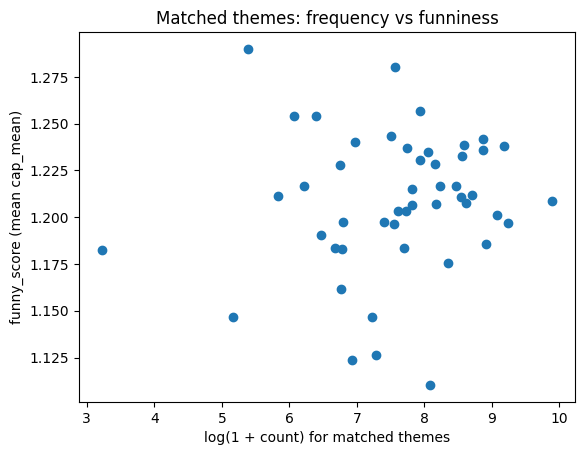

In [30]:
q1_null_hypothesis = "There is no correlation between the frequency of matched themes in image-caption pairs and their funniness score."
q1_alpha = 0.05

# extract diag
diag = cells[(cells['image_theme_id'] == cells['caption_theme_id']) & (cells['count'] > 0)].copy()
diag['log_count'] = np.log1p(diag['count'])

# ensure numeric and drop NaNs
x = pd.to_numeric(diag['log_count'], errors='coerce')
y = pd.to_numeric(diag['funny_score'], errors='coerce')
mask = x.notna() & y.notna()
x = x[mask].to_numpy()
y = y[mask].to_numpy()

# compute spearman and pearson
spearman_res = stats.spearmanr(x, y)
pearson_res  = stats.pearsonr(x, y)

spearman_r, spearman_p = float(spearman_res.statistic), float(spearman_res.pvalue)
pearson_r,  pearson_p  = float(pearson_res.statistic),  float(pearson_res.pvalue)

print(f"Diagonal (matched themes) with count>0: n={len(x)}")
print(f"Spearman r={spearman_r:.3f}, p={spearman_p:.3g}")
print(f"Pearson  r={pearson_r:.3f}, p={pearson_p:.3g}")

# Quick visualization
plt.figure()
plt.scatter(x, y)
plt.xlabel('log(1 + count) for matched themes')
plt.ylabel('funny_score (mean cap_mean)')
plt.title('Matched themes: frequency vs funniness')
plt.show()


In [31]:
print(f"Null hypothesis:\n {q1_null_hypothesis}\n")

# test hypothesis
if spearman_p < q1_alpha:
    print(f"Reject null hypothesis at alpha={q1_alpha} with p={spearman_p:.3g}: significant correlation found.")
else:
    print(f"Fail to reject null hypothesis at alpha={q1_alpha} with p={spearman_p:.3g}: no significant correlation found.")

Null hypothesis:
 There is no correlation between the frequency of matched themes in image-caption pairs and their funniness score.

Fail to reject null hypothesis at alpha=0.05 with p=0.326: no significant correlation found.


From this result, we can say most surely that there are no appearant correlations between the funny_score and how frequent a theme is being used: both correlation tests were small and non significat. There are no evidence of a monotonic or linear association between frequency and funniness among matched themes at alpha = 0.05. 

Take-away: following the 'trends' doesn’t reliably buy you extra laughs, at least not in a way we can detect here.

#### 3.8.4 Q2: Are some image themes inherently funnier?

Here we will test whether image theme predicts caption funniness **after controlling for caption theme**, using contest-clustered standard errors.

Note: this following cell takes some time to run: ~ 2min30s

In [32]:
q2_null_hypothesis = "After controlling for caption theme, image theme has no effect on caption funniness"
q2_alpha = 0.05

# Caption-level model with theme fixed effects and contest-clustered SE
m_img = smf.ols('cap_mean ~ C(image_theme_id) + C(caption_theme_id)', data=pairs).fit(
    cov_type='cluster', cov_kwds={'groups': pairs['contest_id']}
)

# joint Wald test for Image Theme block
# Collect all image-theme dummy coefficient names (excluding intercept and the baseline level)
img_terms = [name for name in m_img.params.index if name.startswith("C(image_theme_id)[T.")]

wald_img = m_img.wald_test(img_terms)   # joint test: all these coefficients == 0
q2_p = float(wald_img.pvalue)


/opt/miniconda3/envs/ada/lib/python3.13/site-packages/statsmodels/base/model.py:1912: FutureWarning:

The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.



In [33]:
print(f"Null hypothesis:\n {q2_null_hypothesis}\n")
# print(f"Joint Wald test (ImageTheme block): chi2={float(wald_img.statistic):.3f}, df={int(wald_img.df_denom)}, p={q2_p:.3g}")

if q2_p < q2_alpha:
    print(f"Rejected successfully null hypothesis at alpha={q2_alpha} with p={q2_p}: image themes differ in funniness (given caption-theme control).")
else:
    print(f"Fail to reject null hypothesis at alpha={q2_alpha} with p={q2_p:.3g}: no evidence of image-theme differences (given caption-theme controls).")

Null hypothesis:
 After controlling for caption theme, image theme has no effect on caption funniness

Rejected successfully null hypothesis at alpha=0.05 with p=0.0: image themes differ in funniness (given caption-theme control).


Ah-ha ! Some image captions are thus inherently funnier than others.

The joint Wald test on the Image Theme block strongly rejects the null hypothesis that image themes have no effect on funniness after controlling for caption theme (p << 0.001, printed as 0.0 due to rounding). In short: even when we hold the caption theme constant, the image theme still shifts expected funniness, meaning some subjects are just naturally better “comedy ladders” than others.

Take-away: you can be equally witty, but if you’re joking on a theme the dataset likes, you’re basically starting with a head start (comedy unfairness, confirmed). Some subject are funnier than other independantly of how funny you are, life's unfair I know...

#### 3.8.5 Q3) Semantic distance: relation with funniness and frequency
This question contains 2 in 1 ! What a deal:
- **Q3a:** Does semantic distance predict funniness (controlling for image & caption themes)?
- **Q3b:** Does semantic distance predict frequency of occurrence (controlling for marginal popularity of themes)?

In [34]:
# similarity wide -> long
sim_long = p3_themes.similarity_wide_to_long(similarity_df)

# merge similarity into pairs and cells
pairs_sim = p3_themes.add_similarity_to_theme_pairs(pairs, sim_long)
cells_sim = p3_themes.add_similarity_to_theme_pairs(cells, sim_long)


In [35]:
# Q3a
q3a = p3_themes.fit_q3a_distance_predicts_funniness(pairs_sim)
print("Q3a distance coef:", q3a.distance_coef, "p:", q3a.distance_pvalue)

q3a_null_hypothesis = "Semantic distance between image and caption themes does not predict caption funniness after controlling for image theme and caption theme (distance coefficient = 0)."
q3a_alpha = 0.05

# Decision statements
if q3a.distance_pvalue < q3a_alpha:
    print(f"Reject null hypothesis at alpha={q3a_alpha}: semantic distance is significantly associated with funniness (given controls).")
else:
    print(f"Fail to reject null hypothesis at alpha={q3a_alpha}: no evidence that semantic distance predicts funniness (given controls).")

Q3a distance coef: -0.0077404364831072 p: 0.0893741774565763
Fail to reject null hypothesis at alpha=0.05: no evidence that semantic distance predicts funniness (given controls).


Okay so, “the weirder the pairing, the funnier the caption” might actually not hold up.

The verdict is ... meh:

The distance coefficient is slightly negative (beta ~ −0.0077) and the p-value (0.089) is in that awkward “almost, but not really” zone. So at alpha=0.05 we don’t have strong evidence that semantic distance reliably boosts funniness once we control for themes.

Also let's observe that the distance coefficient is negative. That means that as image and caption themes get more semantically different, the outcome goes down: here it suggests “more mismatch => slightly less funny” (and here it’s weak/not significant at 0.05).

Take-away: just making the caption theme far away from the image theme doesn’t automatically make it funnier. At the end chaos is not a guaranteed comedy strategy.

In [36]:
# Q3b
q3b = p3_themes.fit_q3b_distance_predicts_frequency(cells_sim)
print("Q3b distance coef:", q3b.distance_coef, "p:", q3b.distance_pvalue)

q3b_null_hypothesis = "to complete"
q3b_alpha = 0.05

# Decision statements
if q3b.distance_pvalue < q3b_alpha:
    print(f"Reject null hypothesis at alpha={q3b_alpha}: semantic distance is significantly associated with frequency (given controls).")
else:
    print(f"Fail to reject null hypothesis at alpha={q3b_alpha}: no evidence that semantic distance predicts frequency (given controls).")

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/statsmodels/genmod/families/family.py:1367: ValueWarning:

Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.



Q3b distance coef: -4.645619998350211 p: 1.965116086927504e-158
Reject null hypothesis at alpha=0.05: semantic distance is significantly associated with frequency (given controls).


But for question 3b, the data does have strong opinions about how often people go for unrelated themes compared to the image one.

Here, the result is loud and clear: semantic distance is very (a lot) strongly associated with frequency (p ~ 0.0), and the coefficient is negative (beta ~ −4.65). Here the negative coeficient clearly shows “more mismatch => much less frequent,” which directly answers whether semantic distance affects funniness and how often people actually make those pairings. Translation: the more semantically distant a caption theme is from the image theme, the less often that pairing happens.

Take-away: contestants mostly play it safe and stay semantically “close”. Wild cross-theme pairings are rare creatures (even if they occasionally land).


## 4.Structural Analysis / What structure of joke is the funniest ?

### 1. Load the data set and make the captions more fluid

Load the data set: 

In [ ]:
# load the data set 
path = str('THEMES_RESULTS_V4/docs_with_themes.csv') # TODO changer avec THEMES_RESULTS_V4/docs_with_themes.csv

df_og = ut.load_docs_with_theme_csv(path)
df = df_og.loc[df_og['kind'] != 'image']

df.head(5)

Make the captions more fluid by: 
- erasing unnecessary punctuations 
- lowercase all the captions 
- handling contractions to normalise all the captions 
        -> necessary for comparison 

In [ ]:
# check for missing values and fill NaN w/ empty string or remove them
import warnings
warnings.filterwarnings("ignore")
print(f"missing values in caption: {df['text'].isna().sum()}")
df["text"] = df["text"].fillna("")

# erase unnecessary punctuations :
df["text"] = df["text"].str.replace(r"[--]", " ", regex=True)
df["text"] = df["text"].str.replace(r"[.,?]", " ", regex=True)

# lowercase : 
df["text"] = df["text"].str.lower()

# contractions :
df["text"] = df["text"].apply(lambda x: contractions.fix(x))   

print(df["text"].head()) # check

## JE METTRAI ÇA DANS DATA CLEANING ? TODO

### 4.2 Are longer jokes funnier than shorter ones? What about jokes with more complex vocabulary?

The average of words and characters of the entire data set: 

In [ ]:
# words
df["word_counts"] = [len(line.split()) for line in df["text"]]

# characters 
df["length"] = [len(line) for line in df["text"]]

# average of words and characters
print(f"Average word count: {df['word_counts'].mean():.2f}")
print(f"Average character count: {df['length'].mean():.2f}")
print(f"Data set size: {len(df)} captions")

#### 4.2.1 Does the amount of words used in the caption influence the funniness score in general?

**Use of Pearson r for the correlation analysis and ttest:**

The final graph was not outputed in the nootebook because it is way to heavy, feel free to run it (it works).

In [ ]:
# style of plot
plt.style.use('default')
sns.set_palette("husl")

# proportions
df['total_votes'] = ut.proportion_calculation(df)['total_votes']
df['prop_not_funny'] = ut.proportion_calculation(df)['prop_not_funny']
df['prop_somewhat_funny'] = ut.proportion_calculation(df)['prop_somewhat_funny']
df['prop_funny'] = ut.proportion_calculation(df)['prop_funny']

df['funny_score_weighted'] = ut.proportion_calculation(df)['funny_score_weighted']
df['success_metric'] = ut.proportion_calculation(df)['success_metric']

# correlation analysis (print and plot) 
#ut.print_and_plot_proportion_correlation(df, word_col='word_counts', char_col = 'length', score_col = 'success_metric', 
#                                        max_words = 100, max_chars = 400, use_plotly=True, sample_size = 10000)

![Results](4_2_1.png) #TODO changer le path to utils/4_2_1.png

In [ ]:
# statistical test for performance comparison & word count performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance comparison:")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nword count comparison:")
print(f"top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

print(f"\nlength count comparison:")
print(f"top performers: {top_captions['length'].mean():.1f} ± {top_captions['length'].std():.1f}")
print(f"bottom performers: {bottom_captions['length'].mean():.1f} ± {bottom_captions['length'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"t-test p-value words: {p_val:.4f}")

t_stat, p_val = ttest_ind(top_captions['length'], bottom_captions['length'])
print(f"t-test p-value characters: {p_val:.4f}")

*Interpretation:*

| **Metric** | **Top 20%** | **Bottom 20%** |
|-----------|-----------|--------------|
| Mean word count | 10.3 | 10.9 |
| Standard deviation (word) | 4.6 | 5.7 |
| Mean character count | 51.9 | 55.5 |
| Standard deviation (characters) | 23.5 | 29.9 |

We can see that the correlations between word count and funniness (~-0.038) and between character count and funniness (~-0.043) are extremely close to 0, indicating that there is almost no linear association between length and funny score. 

The downward regression lines found in the scatterplots above show that, on average, longer captions score *slightly* less funny, but the cloud of points is extremely wide, meaning that this observation is irrelevant. 

The boxplot shows that low, medium, and high performance groups all have overlapping interquartile ranges of word counts, reinforcing that funny and unfunny captions largely share the same length distribution.

We can also see that the p-values are at ~0.0000, which makes even misnuscule differences in score depending on funniness score statistically significant, but because it is a huge sample size, it has not a meaningful influence: in this case, the effect of length on funniness is statistically detectable but negligible. 

Top 20% captions have 10.3 words vs 10.9 words for the bottom 20%: the difference is ~0.6 words, which signals a very negligible and small effect on length

**Using another technique to confirm the results**

PARTIAL CORRELATION: to control for potential confounders
- why is it useful? It controls for confounding variables (maybe certain joke categories genre puns/stories) are both long AND funnier 
- what does it add? a more purified relationship between length & funniness 
=> if it drops near 0, length might not matter 

In [ ]:
## control for # of votes (sample size effect)
partial_corr_votes, p_partial_corr_votes, _, _ =  ut.partial_correlation_manual(df, 'word_counts', 'success_metric', ['votes'])
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
print(f"Partial corr: {partial_corr_votes:.3f} vs simple corr: {corr_word_score:.3f}")
print(f"p-value: {p_partial_corr_votes:.4f}")

*Intrepretation:*

The p-value is essentially equal to zero, which indicates that the correlation is statistically significant, but we have that the simple correlation between word count and the success metric is at -0.038, with a partial correlation controlling for votes at -0.039, implying that it's negligible in practice. 

So, to conclude, and as obtained before, the relationship between length and funniness is statistically reliable but extremely weak in practical terms.

#### 4.2.2 Does the amount of words used in the caption influence the funniness score depending on theme?

In [ ]:
theme_corr_df, df_theme = ut.theme_wordcount_analysis(df)

*Interpretation:*

We can see that most themes have correlations between word count and funniness in the range about -0.08 to 0, with highly significant p-values because n per theme is large. But, the closer the correlation is to 0, the weaker the linear relationship is. 

We can observe that the curves look like worse scores are given to captions with more words, but it's important to be careful and to look at the numbers. Why be careful? There is a substantial scatter in word counts within each themeand funny scores, plus, the average length is at 10 either way, with correlation or not, as seen before, so ength alone is a weak predictor of outcome.

Given the large sample sizes, these effects are statistically significant for many themes but remain modest in practical terms, indicating that theme and content may matter far more than sheer length for predicting funniness: word count has no clear relationship with the score.

#### 4.2.3 Do some words or does some kind of vocabulary richness correlate with higher scores (in general)?

Analysis of vocabulary richness using TTR (type-token ratio) where: 
- the mathematical computation is given by (#unique_words) / (total_words)
- it ranges from 0 (= no words or all words are identical) to 1 (=every word is unique)

In [ ]:
# calculation of vocabulary richness metrics

# check if we already have these columns & remove them if they exist (in case of problems)
columns_to_remove = ['ttr', 'unique_words', 'total_words']
existing_cols = [col for col in columns_to_remove if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# calculate vocab richness for all captions
vocab_metrics = ut.calculate_vocabulary_richness(df['text'], remove_stopwords=True)

# new columns to the main DataFrame
df = pd.concat([df, vocab_metrics], axis=1)

# some stats
print(f"average TTR: {df['ttr'].mean():.3f}")
print(f"average unique words per caption: {df['unique_words'].mean():.1f}")
print(f"average total words per caption: {df['total_words'].mean():.1f}")
print(f"dataset size: {len(df)} captions")


In [ ]:
top_captions = df[df['success_metric'] >= top_cutoff].dropna(subset=['ttr', 'unique_words', 'total_words'])
bottom_captions = df[df['success_metric'] <= bottom_cutoff].dropna(subset=['ttr', 'unique_words', 'total_words'])

print(f"\nvocab richness comparison")
print("top performers:")
print(f"  TTR: {top_captions['ttr'].mean():.3f} ± {top_captions['ttr'].std():.3f}")
print(f"  Unique words: {top_captions['unique_words'].mean():.1f} ± {top_captions['unique_words'].std():.1f}")
print(f"  Total words: {top_captions['total_words'].mean():.1f} ± {top_captions['total_words'].std():.1f}")

print("\nbottom:")
print(f"  TTR: {bottom_captions['ttr'].mean():.3f} ± {bottom_captions['ttr'].std():.3f}")
print(f"  Unique words: {bottom_captions['unique_words'].mean():.1f} ± {bottom_captions['unique_words'].std():.1f}")
print(f"  Total words: {bottom_captions['total_words'].mean():.1f} ± {bottom_captions['total_words'].std():.1f}")

<!-- The above code cell outputs the following:
```bash
    average TTR: 0.989
    average unique words per caption: 4.9
    average total words per caption: 5.0
    dataset size: 2292678 captions
``` -->

In [ ]:
# Ensure no NaNs for t-test
top_ttr = top_captions['ttr'].dropna()
bottom_ttr = bottom_captions['ttr'].dropna()
top_unique = top_captions['unique_words'].dropna()
bottom_unique = bottom_captions['unique_words'].dropna()
top_total = top_captions['total_words'].dropna()
bottom_total = bottom_captions['total_words'].dropna()

# t-tests
t_stat_ttr, p_val_ttr = ttest_ind(top_ttr, bottom_ttr)
t_stat_unique, p_val_unique = ttest_ind(top_unique, bottom_unique)
t_stat_total, p_val_total = ttest_ind(top_total, bottom_total)

print(f"\nT-TESTS)")
print(f"TTR (p-value) = {p_val_ttr:.4f} {'***' if p_val_ttr < 0.001 else '**' if p_val_ttr < 0.01 else '*' if p_val_ttr < 0.05 else 'ns'}")
print(f"Unique words (p-value) = {p_val_unique:.4f} {'***' if p_val_unique < 0.001 else '**' if p_val_unique < 0.01 else '*' if p_val_unique < 0.05 else 'ns'}")
print(f"Total words (p-value) = {p_val_total:.4f} {'***' if p_val_total < 0.001 else '**' if p_val_total < 0.01 else '*' if p_val_total < 0.05 else 'ns'}")

# --- CORRELATIONS ---
# Drop rows with NaN or inf for correlation
df_corr = df[['ttr', 'unique_words', 'total_words', 'success_metric']].replace([np.inf, -np.inf], np.nan).dropna()

corr_ttr, p_corr_ttr = pearsonr(df_corr['ttr'], df_corr['success_metric'])
corr_unique, p_corr_unique = pearsonr(df_corr['unique_words'], df_corr['success_metric'])
corr_total, p_corr_total = pearsonr(df_corr['total_words'], df_corr['success_metric'])

print(f"\ncorrelation w/ success metric")
print(f"TTR correlation: {corr_ttr:.3f} (p-value: {p_corr_ttr:.4f})")
print(f"unique words correlation: {corr_unique:.3f} (p-value: {p_corr_unique:.4f})")
print(f"total words correlation: {corr_total:.3f} (p-value: {p_corr_total:.4f})")

# plot
df = df.copy()
df['performance_group'] = pd.qcut(df[success_metric_col], q=3, labels=['Low', 'Medium', 'High'])
ut.plot_linguistic_metrics(df, top_captions, bottom_captions, corr_ttr, corr_unique)



*Interpretation:*
From the p-values (close to 0) for TTR, unique words, and total words mean the group means are not all equal; the observed differences are very unlikely under the null of “no difference,” given the large sample size. Plus, the correlations with success metric are of 0.012 (TTR), −0.047 (unique words), and −0.048 (total words), which are considered negligible: they explain less than 0.3% of the variance in the funny score, which is effectively no predictive power.

The very small p‑values on these correlations again reflect statistical, not practical, significance: with very large datasets, even minuscule correlations become “significant” while still being useless for prediction or interpretation.

The plots match this story: the scatterplots are almost clouds with no visible trend, and the group distributions of TTR overlap heavily, even though the tests are significant.

These results show that TTR and the total word count differ reliably between our performance groups, but each has an extremely small relationship with the success (funny) score, likely because the sample size is huge. In other words, the effects are statistically significant but not practically important.



## 5. Semantic Analysis / Is there a type of joke or humor which is funnier ?


### 5.1. Classifying the quotes 
In order to make the task easier, we classified each caption to one of the Berger’s humor categories ;

| Categories of Humour | What they mean |
|-----------|-----------|
|Language|Verbal humor, Allusion, Irony, Puns, Repartee, Wit, Ridicule|
|Logic|Ideational humor, Absurdity, Coincidence, Conceptual surprise, Outwitting, Caught out, Misunderstanding|
|Identity|Existential humor, Parody, Rigidity, Malicious pleasure, Condescension, Deceitful behavior, Self-deprecation|
|Action|Physical/ non-verbal humour, Peculiar face, Peculiar music, Clumsiness, Repulsive behavior|

With the help of Ollama and gpt-oss:120b (model of LLM), the top and worst 25 caption of each contest was classified. The restriction comes from the time it takes to run each classification ≈ 2s, and if you multiply this by ≈5000 caption per ≈380 contest, it would take around 49 days to run, plus there is a hourly and weekly limit using ollama's cloud...
Then the LLM classified each caption to all of the categories with a percentage (SEE CODE HERE classify_captions()), since one caption could be mixing 2 or more types of humor, and were cleaned (because the LLM do not always respect the format). The finals results look like this :   


In [ ]:
pd.read_csv(str(CLASS_DIR)+'/612_cleaned.csv').head(10)

### 5.2 Analysing the results

#### 5.2.1 Visualisation and descritpive statistics

Once all the captions were classified, some observables were added : mean of the caption, the contest id, the dominant category as well as the dominant value. All the data was then saved to a new csv; super.csv. The analysis of super csv was then done.

In [ ]:
df=pd.read_csv(str(CLASS_DIR)+'/super.csv')

cols = ['Logic', 'Identity', 'Action', 'Language', 'mean']

fig_pair = viz.plot_df_pairgrid_plotly(df,cols=cols,title='Pairwise relationships')
fig_hist = viz.plot_histograms(df,cols=cols,title='Marginal distributions')
fig_comp= viz.plot_dominant_vs_mean(df,title='Dominant Cat vs Mean')

fig_pair.show()
fig_hist.show()
fig_comp.show()

stats = df[['Logic','Identity','Action','Language','mean']].describe()
print('================================ Descriptive statistics ========================')
print(stats)

viz.descriptive_analysis(df)



From the first graph, the scatters plots from the different categories make sense following 1-x line because for low category1 percetages you can have high values of other categores, and as the categorie values augments, the others diminish. Another suprising result is that there are some caption that are classified to Action which is not possible since it is non-verbal humor showing that the task did not perform very well... Furthermore it seems that there are no relationships between the caption humor categories and the caption mean. The litlle space between the both groups accouring at mean=1.2 to mean=1.5 is explained by our subsampling of the first and last 25 captions. <br>
<br>
The histograms of the categories and mean show that logic and language are the most higly common types of humor, eventhough every type of humor is present showed by the high peaks of each distribution at the begining. The mean distribution surely follows an exponential (VERIFIER AVEC LES GRAPH AU DEBUT) distribution, but the hole between mean=1.15 to mean=1.45 is explained by the subsampling again.<br>
<br>
Finnaly the last scatter plot with the dominat categories vs the mean do not show any specific relationship. The separation of the 2 groups is again explained by the subsampling.<br>
<br>
The first descriptive statistics shows that, again, logic and language are the higly common types of humor, with their respective means of 0.38 and 0.50, and Identity humor and Action are not very present humour since their 75% quantiles are 0.05. Eventhough, their max values suggest that there are some caption highly related to those categories (eventhough Action is not accurate). <br>
<br>
The scond statistics shows that there is realy no effects from the categories to the means since they are very very close in the means. The bar plots show the same thing.


#### 5.2.2 A bit more advance statistics

The first results suggest strongly that there is no effect but in order to be sure, some more statistics were done

In [ ]:
viz.heatmap(df,['Logic', 'Identity', 'Action', 'Language', 'mean'])

mod= smf.ols(formula='mean~ Logic + Identity + Action + Language',data=df)
res = mod.fit()
print(res.summary())

The corrolation matrixn now reaaly shows that there are no corrolations between the humor categories and the caption means. However, it is interesting to notice the high negative correlation between Language and Logic. From the definitions, both categories seemed a bit related, but at least the classifier, not very reliable, did not consider them together.

The regression now really indicates that there are no effect of the humor category with the mean, with an explained variance of 0.001, and non-significant coeeficients.

## 6. Timing and Context Analysis



### 6.1 Context Analysis

As explained in our README, we have eventually decided to drop our Contextual Analysis after exploring a reduced snipet of the GDELT database. Here, you can have insight into what it looks like :  

---
```python
    #dataset_path = file_path = pd.read_txt(r"C:\Users\hanna\ADA\2025\newyorker_caption_contest\data\510.csv")
    dataset_path = r"C:\Users\hanna\ADA\2025\additional_dataset\GDELT.MASTERREDUCEDV2.txt"
    from itertools import islice

    with open(dataset_path, "r") as f:
        for line in f.readlines()[:5]:
            print(line.strip())
```
---
The code above outputs the following:

```bash
    Date	Source	Target	CAMEOCode	NumEvents	NumArts	QuadClass	Goldstein	SourceGeoType	SourceGeoLat	SourceGeoLong	TargetGeoType	TargetGeoLat	TargetGeoLong	ActionGeoType	ActionGeoLat	ActionGeoLong
    19790101	AFR	FRA	043	1	4	1	2.8
    19790101	AFR	FRA	050	2	9	1	3.5
    19790101	AFR	FRAGOV	043	2	19	1	2.8	1	46	2	1	46	2	1	46	2
    19790101	AFR	ZMB	100	2	18	3	-5
```

As you can see, the data goes back to January 1rst 1979 and is quite a swiss cheese. More specifically, we are missing quite a lot of data in each line. Each one of them represent a new entry updated each 15mins automatically by GDELT.

Finally, this specific file took a really long time to download as it is 6GB (even if it is a reduced version) and really hard to be found on the GDELT website.

We also tried downloading the time window of interest for our dataset which is from 2016 to 2024. You can download it yourself by using the python script [GDELT_dataloader.py](utils/GDELT_dataloader.py) for a specified datetime range. We realised while downloading that for a 30 days period, we already had 3GB or so of raw data. For the whole dataset from 2016 to 2024 this would give us an **enormous augmented dataset of 288GB!**

This dataset is simply way to large to deal with on our personal computer and also the data wrangling involved to clean it is in itself a whole project. This outcome further encouraged us to drop the idea of performing contextual analysis, since the rest of our findings encourages us to follow other analysis ideas. 

### Timing Analysis
We have added dates conresponding to each contest using a function "add_contest_dates". 
For reference : 

In [ ]:
contest_no_dates = pd.read_json(JSON_DIR)
contest_no_dates.head()

We then added the relevant dates like this : 

In [ ]:
contest_with_dates = add_contest_dates(contest_no_dates)
contest_with_dates.head()

Then proceeded to plot the dates on the X-axis, Y1-axis corresponds the number of submitted captions and Y2-axis corresponds to mean funniness overtime.


In [ ]:
plot_captions_and_funniness_timeline_plotly(CSV_CLEAN_DIR, contest_with_dates, sigma=4)

This function generates an interactive timeline visualization showing how contest popularity and average funniness evolve over time. For each contest between 510 and 895, it loads the corresponding cleaned CSV file (when available) and computes two summary metrics: the number of submitted captions and the mean funniness score across captions.

These contest-level metrics are then merged with publication dates, allowing the data to be ordered chronologically. This enables a direct comparison of how engagement and perceived humor change over the lifespan of the dataset.

To improve readability, both time series are smoothed using a Gaussian filter (`gaussian_filter1d`) with standard deviation σ (which we have set at 4). This Gaussian smoothing acts as a low-pass filter, reducing short-term noise while preserving long-term trends. The smoothed curves are included solely as visual guides to support interpretation and are not used to assess correlation or draw statistical conclusions.

The visualization is built using Plotly with two overlaid y-axes: the left axis represents the number of captions, while the right axis shows the mean funniness score. Raw values are displayed as semi-transparent markers, and the smoothed trends are overlaid as continuous lines. Interactive hover tooltips and a unified hover mode facilitate comparison between the two metrics over time.

Finally, the figure is saved as an HTML file for integration into the website and displayed directly in the notebook. The merged dataset used for the plot is returned to allow further analysis if needed.

The goal of this analysis is not to enforce correlation, but to provide visual support and open up a conversation about comedic timing.


## 7. Conclusion

To conclude, up until now, we were not only able to dive into the provided NewYorker’s dataset, but we also managed to perform : 

Filtering and transformation of the data through data wrangling. This confirmed that we are on a good track in handling the data in its size, and also that we were able to verify that we understood the data’s format (CSV, JSON, png…). Through different methods to fill in missing data, as well as plots and graphs, we were able to visualize the main features of the dataset. We still need to finish our functions that correct the entire dataset.
We also considered ways to enrich the data, through an additional dataset, but also using calculations and generative AI for image descriptions.
Furthermore, we are confident that our proposed plan is not only feasible, but highly likely to give us an engaging and gripping datastory. When it comes to the methods we have found, these will be further dived into in the following weeks, as exposed in our proposed timeline. We have proposed statstical means which will be used to answer to dig deeper into our research questions.

Ultimately, we are looking forward to not only dive deeper, but also construct a robust story around the question : What makes a joke funny ?